rows used: 56
missing: 5
count    56.000000
mean     40.821429
std      12.867305
min      18.000000
25%      31.750000
50%      40.500000
75%      53.000000
max      59.000000
Name: age, dtype: float64
mean: 40.82142857142857
median: 40.5
sample SD: 12.867304786455183
IQR: 21.25
possible outliers: 0


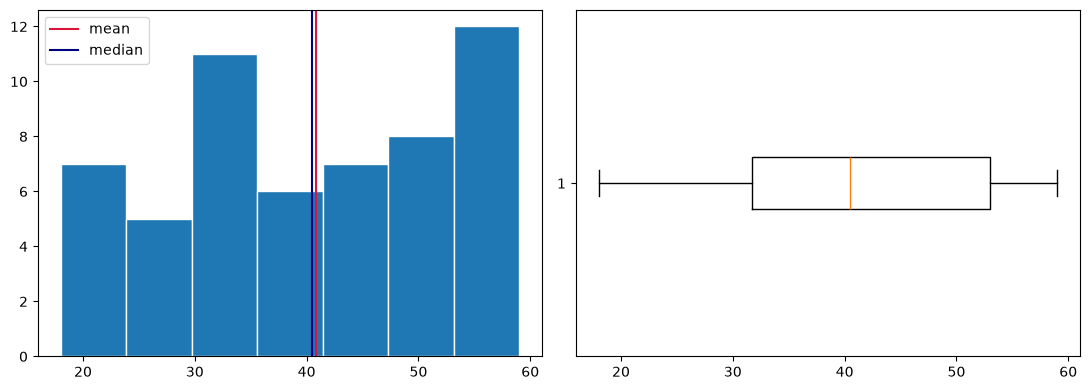

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../customers.csv")

s = pd.to_numeric(df["age"], errors="coerce").dropna()

print("rows used:", s.size)
print("missing:", df["age"].isna().sum())
print(s.describe(percentiles=[0.25, 0.5, 0.75]))

q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("mean:", s.mean())
print("median:", s.median())
print("sample SD:", s.std(ddof=1))
print("IQR:", iqr)
print("possible outliers:", ((s < lower) | (s > upper)).sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(s, bins="auto", edgecolor="white")
axes[0].axvline(s.mean(), color="crimson", label="mean")
axes[0].axvline(s.median(), color="navy", label="median")
axes[0].legend()
axes[1].boxplot(s, orientation="horizontal")
plt.tight_layout()
plt.show()